In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from pathlib import Path

# Load customer data from MySQL
import sys
sys.path.insert(0, str(Path.cwd().resolve().parent))

from database.db_connection import get_engine

engine = get_engine()

try:
    customers = pd.read_sql(
        """
        SELECT
            Customer_ID,
            Age,
            Total_Orders,
            Total_Spent
        FROM customers
        """,
        engine
    )
finally:
    engine.dispose()

print("Dataset shape:", customers.shape)
display(customers.head())


Dataset shape: (40000, 4)


,Customer_ID,Age,Total_Orders,Total_Spent
0,CUST00000001,48,5,40098.48
1,CUST00000002,73,8,63676.24
2,CUST00000003,31,0,0.00
3,CUST00000004,41,5,288324.84
4,CUST00000005,53,4,69265.75


In [3]:

# Select features for customer segmentation
features = ["Total_Spent", "Total_Orders", "Age"]

X = customers[features].copy()

# Check for missing and infinite values
print("Missing values:\n", X.isnull().sum())
print("Infinite values:\n", np.isinf(X).sum())

# Remove records with invalid feature values, if any
valid_rows = X.notna().all(axis=1) & np.isfinite(X).all(axis=1)

X = X.loc[valid_rows]
customers_model = customers.loc[valid_rows].copy()

print("Records available for modeling:", len(X))


Missing values:
 Total_Spent     0
Total_Orders    0
Age             0
dtype: int64
Infinite values:
 Total_Spent     0
Total_Orders    0
Age             0
dtype: int64
Records available for modeling: 40000


In [4]:

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled feature shape:", X_scaled.shape)


Scaled feature shape: (40000, 3)


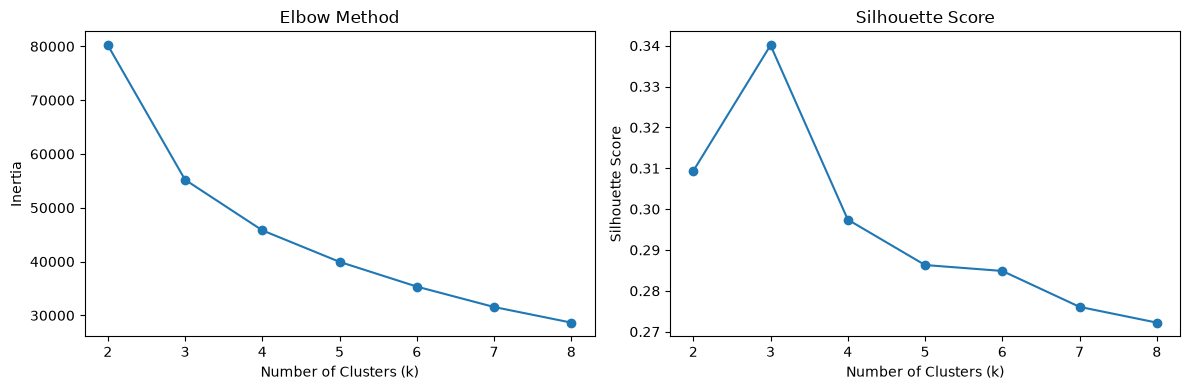

   Clusters     Inertia  Silhouette Score
0         2  80215.7677            0.3093
1         3  55212.8799            0.3401
2         4  45809.4936            0.2974
3         5  39949.4448            0.2863
4         6  35352.1542            0.2849
5         7  31560.2004            0.2761
6         8  28655.3422            0.2722


In [5]:

inertias = []
silhouette_scores = []
k_values = range(2, 9)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    inertias.append(model.inertia_)
    silhouette_scores.append(
        silhouette_score(
            X_scaled,
            labels,
            sample_size=min(5000, len(X_scaled)),
            random_state=42
        )
    )

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(list(k_values), inertias, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (k)")
axes[0].set_ylabel("Inertia")

axes[1].plot(list(k_values), silhouette_scores, marker="o")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of Clusters (k)")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

print(pd.DataFrame({
    "Clusters": list(k_values),
    "Inertia": inertias,
    "Silhouette Score": silhouette_scores
}).round(4))


In [6]:

# Train the final model with 3 customer segments
final_k = 3

kmeans = KMeans(
    n_clusters=final_k,
    random_state=42,
    n_init=10
)

customers_model["Cluster"] = kmeans.fit_predict(X_scaled)

print("Customer count by cluster:")
print(
    customers_model["Cluster"]
    .value_counts()
    .sort_index()
)

print("\nFinal silhouette score:")
print(round(silhouette_score(
    X_scaled,
    customers_model["Cluster"],
    sample_size=min(5000, len(X_scaled)),
    random_state=42
), 4))


Customer count by cluster:
Cluster
0    18390
1     9737
2    11873
Name: count, dtype: int64

Final silhouette score:
0.3401


In [7]:

cluster_summary = (
    customers_model
    .groupby("Cluster")
    .agg(
        Customers=("Customer_ID", "count"),
        Average_Age=("Age", "mean"),
        Average_Orders=("Total_Orders", "mean"),
        Average_Spent=("Total_Spent", "mean"),
        Median_Spent=("Total_Spent", "median")
    )
    .round(2)
)

cluster_summary["Customer_Percentage"] = (
    cluster_summary["Customers"]
    / cluster_summary["Customers"].sum()
    * 100
).round(2)

display(cluster_summary)


,Customers,Average_Age,Average_Orders,Average_Spent,Median_Spent,Customer_Percentage
Cluster,,,,,,
0,18390,28.79,3.72,77663.92,71151.00,45.98
1,9737,53.23,4.93,47849.23,38577.22,24.34
2,11873,30.70,7.05,239823.04,220574.85,29.68


In [8]:

import plotly.express as px

fig = px.scatter(
    customers_model,
    x="Total_Orders",
    y="Total_Spent",
    color="Cluster",
    hover_data=["Customer_ID", "Age"],
    title="Customer Segmentation: Spending vs Orders",
    labels={
        "Total_Orders": "Total Orders",
        "Total_Spent": "Total Spending (₹)",
        "Cluster": "Customer Segment"
    },
    opacity=0.65
)

fig.update_layout(
    template="plotly_white",
    xaxis_title="Total Orders",
    yaxis_title="Total Spending (₹)"
)

fig.show()


In [9]:

import joblib
from pathlib import Path

# Create the models directory
models_dir = Path.cwd().resolve().parent / "models"
models_dir.mkdir(parents=True, exist_ok=True)

# Save the trained model and scaler
joblib.dump(kmeans, models_dir / "customer_kmeans.pkl")
joblib.dump(scaler, models_dir / "customer_scaler.pkl")

# Save customer IDs and their assigned segments
customer_clusters = customers_model[
    ["Customer_ID", "Cluster"]
].copy()

customer_clusters.to_csv(
    models_dir / "customer_clusters.csv",
    index=False
)

print("Customer segmentation artifacts saved successfully!")
print("Saved to:", models_dir)


Customer segmentation artifacts saved successfully!
Saved to: D:\projects\RetailIQ\models
